In [10]:
!apt-get -qq update
!apt-get -qq install -y libdb-dev libdb1-compat db-util
%pip install -q berkeleydb scikit-learn matplotlib

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [19]:
import json
from collections import Counter
import shelve
import numpy as np
from berkeleydb import hashopen
import os
import shutil
import subprocess
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

In [2]:
from google.colab import files
uploaded = files.upload()

Saving embeddings.db to embeddings.db
Saving papers.json to papers.json


In [11]:
with open("papers.json", "r", encoding="utf-8") as f:
    papers = json.load(f)

print("Top-level JSON type:", type(papers).__name__)
print("Number of records:", len(papers))

sample_pmid = next(iter(papers))
sample_record = papers[sample_pmid]

print("\nSample PMID:", sample_pmid)
print("Fields in the sample record:", list(sample_record.keys()))
print("Sample title:", sample_record["ArticleTitle"])
print("Sample query label:", sample_record["query"])

label_counts = Counter(
    record.get("query", "Unknown")
    for record in papers.values()
)

print("\nNumber of records per query label:")
print(label_counts)

Top-level JSON type: dict
Number of records: 1995

Sample PMID: 37961728
Fields in the sample record: ['AbstractText', 'ArticleTitle', 'query']
Sample title: Cardiovascular and Neurological Outcomes in Patients Treated with Edoxaban for Atrial Fibrillation and Characteristics in Patients with Cancer.
Sample query label: Alzheimers

Number of records per query label:
Counter({'Alzheimers': 995, 'Cancer': 995, 'Both': 5})


In [27]:
dump_path = "embeddings_dump.txt"
converted_db_path = "embeddings_converted.db"

db_dump_command = shutil.which("db_dump185")
db_load_command = (
    shutil.which("db_load")
    or shutil.which("db5.3_load")
)

with open(dump_path, "wb") as dump_file:
    subprocess.run(
        [db_dump_command, "embeddings.db"],
        stdout=dump_file,
        check=True
    )

subprocess.run(
    [db_load_command, "-f", dump_path, converted_db_path],
    check=True
)

print("Database conversion completed.")

Database conversion completed.


In [15]:
raw_db = hashopen(converted_db_path, flag="r")
embedding_shelf = shelve.Shelf(raw_db)

vectors = []
labels = []
matched_pmids = []
missing_pmids = []
invalid_pmids = []

for pmid, metadata in papers.items():
    embedding = embedding_shelf.get(str(pmid))

    if embedding is None:
        missing_pmids.append(pmid)
        continue

    if hasattr(embedding, "detach"):
        embedding = embedding.detach().cpu().numpy()

    embedding = np.asarray(embedding, dtype=np.float32).reshape(-1)

    if embedding.shape[0] != 768:
        invalid_pmids.append((pmid, embedding.shape[0]))
        continue

    vectors.append(embedding)
    labels.append(metadata.get("query", "Unknown"))
    matched_pmids.append(pmid)

embedding_shelf.close()

if not vectors:
    raise ValueError("No valid embeddings were matched with the metadata.")

X = np.vstack(vectors)
labels = np.asarray(labels)
matched_pmids = np.asarray(matched_pmids)

print("Number of aligned records:", len(matched_pmids))
print("Embedding matrix shape:", X.shape)
print("Number of PMIDs without embeddings:", len(missing_pmids))
print("Number of embeddings with an unexpected dimension:", len(invalid_pmids))
print("Aligned records per label:", Counter(labels))

Number of aligned records: 1995
Embedding matrix shape: (1995, 768)
Number of PMIDs without embeddings: 0
Number of embeddings with an unexpected dimension: 0
Aligned records per label: Counter({np.str_('Alzheimers'): 995, np.str_('Cancer'): 995, np.str_('Both'): 5})


In [18]:
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X)

print("PCA result shape:", X_pca.shape)
print("Explained variance ratio per component:", pca.explained_variance_ratio_)
print(
    "Cumulative explained variance ratio:",
    pca.explained_variance_ratio_.sum()
)

PCA result shape: (1995, 3)
Explained variance ratio per component: [0.1661857  0.0679341  0.04533731]
Cumulative explained variance ratio: 0.27945712


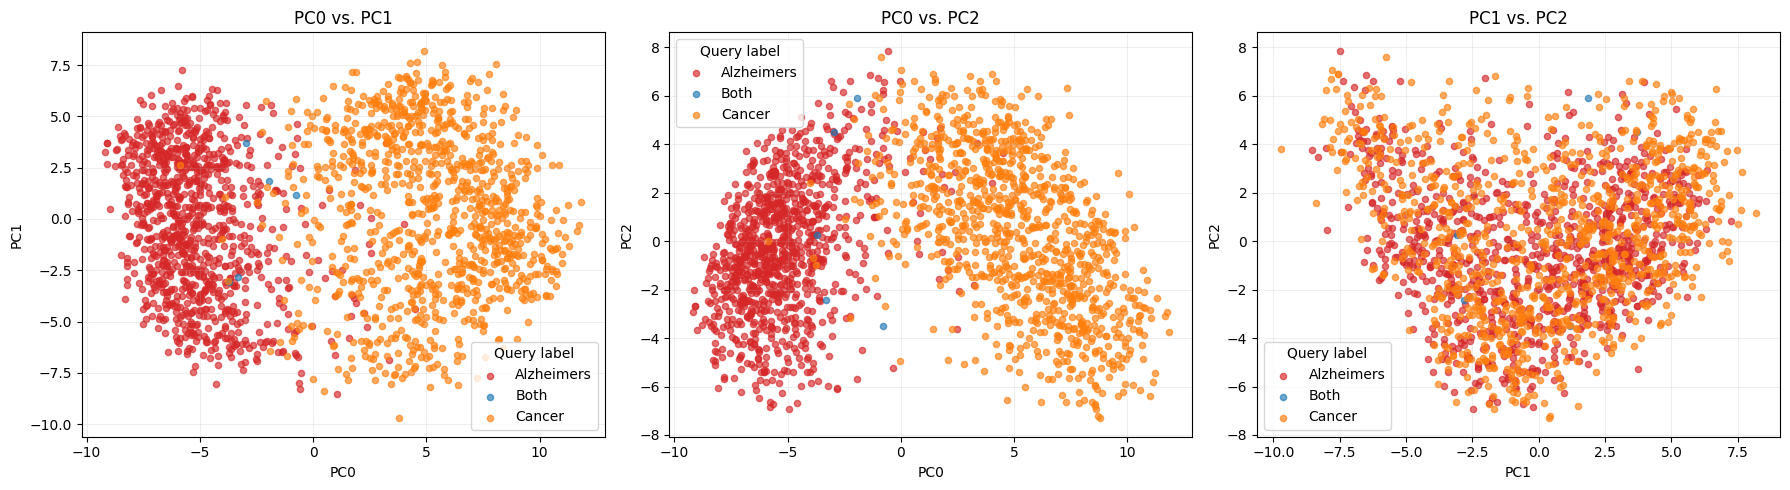

In [26]:
label_colors = {
    "Alzheimers": "tab:red",
    "Cancer": "tab:orange",
    "Both": "tab:blue",
}

component_pairs = [
    (0, 1),
    (0, 2),
    (1, 2),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (i, j) in zip(axes, component_pairs):
    for label in sorted(set(labels)):
        mask = labels == label

        ax.scatter(
            X_pca[mask, i],
            X_pca[mask, j],
            label=label,
            color=label_colors.get(label, "gray"),
            alpha=0.65,
            s=20
        )

    ax.set_xlabel(f"PC{i}")
    ax.set_ylabel(f"PC{j}")
    ax.set_title(f"PC{i} vs. PC{j}")
    ax.legend(title="Query label")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()